In [1]:
# Cell 1: Environment setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import pickle
import warnings

from sklearn.decomposition import PCA
from pykalman import KalmanFilter
from arch import arch_model
from scipy.signal import medfilt

# Reproducibility
np.random.seed(42)

# Display settings
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.6f}')

# Suppress library noise
warnings.filterwarnings('ignore')

# ---- Global constants (used across all cells) ----

ASSETS = ['SPY', 'GLD', 'TLT']

# Data split
IS_START = '2010-01-01'
IS_END   = '2018-12-31'
OOS_START = '2019-01-01'
OOS_END   = '2025-01-01'

# PCA
PCA_MIN_TRAIN = 252      # 1 year minimum for PCA fit

# Kalman
KF_Q = 0.1              # transition covariance
KF_R = 1.0               # observation covariance

# GARCH
GARCH_MIN_TRAIN = 504    # 2 years for stable estimation
GARCH_REFIT = 63         # quarterly refit
GARCH_MAX_PERSIST = 0.98

# Regime (annualized volatility thresholds)
VOL_ENTER_ANN = 0.20   # was 0.18
VOL_EXIT_ANN  = 0.15   # was 0.14
VOL_ENTER_DAILY = VOL_ENTER_ANN / np.sqrt(252)
VOL_EXIT_DAILY  = VOL_EXIT_ANN / np.sqrt(252)
MIN_REGIME_DURATION = 15

# Portfolio weights (per regime)
WEIGHTS_CALM      = {'SPY': 0.70, 'GLD': 0.15, 'TLT': 0.15, 'Cash': 0.00}
WEIGHTS_TURBULENT = {
    'SPY':  0.10,
    'GLD':  0.30,
    'TLT':  0.20,
    'Cash': 0.40,
}

# ---- Portfolio weights (per regime) ----

# Calm: risk-on, fully invested



# All assets including cash
ALL_ASSETS = ['SPY', 'GLD', 'TLT', 'Cash']

# Transaction costs
TC_BPS = 10              # 10 basis points

print("Setup complete.")
print(f"Assets: {ASSETS}")
print(f"In-Sample:  {IS_START} → {IS_END}")
print(f"Out-Sample: {OOS_START} → {OOS_END}")

# ---- Helper functions (used across cells) ----

def smooth_regimes(regimes, min_dur=15):
    """Merge short regimes (< min_dur days) into the previous regime."""
    r = np.array(regimes.values, copy=True)
    n = len(r)
    i = 0
    while i < n:
        j = i
        while j < n and r[j] == r[i]:
            j += 1
        if (j - i) < min_dur and i > 0:
            r[i:j] = r[i-1]
        i = j
    return pd.Series(r, index=regimes.index, name='Regime')

Setup complete.
Assets: ['SPY', 'GLD', 'TLT']
In-Sample:  2010-01-01 → 2018-12-31
Out-Sample: 2019-01-01 → 2025-01-01


In [2]:
print("WEIGHTS_CALM:", WEIGHTS_CALM)
print("WEIGHTS_TURBULENT:", WEIGHTS_TURBULENT)
print("Sum Calm:", sum(WEIGHTS_CALM.values()))
print("Sum Turbulent:", sum(WEIGHTS_TURBULENT.values()))
print("ALL_ASSETS:", ALL_ASSETS)

WEIGHTS_CALM: {'SPY': 0.7, 'GLD': 0.15, 'TLT': 0.15, 'Cash': 0.0}
WEIGHTS_TURBULENT: {'SPY': 0.1, 'GLD': 0.3, 'TLT': 0.2, 'Cash': 0.4}
Sum Calm: 1.0
Sum Turbulent: 1.0
ALL_ASSETS: ['SPY', 'GLD', 'TLT', 'Cash']


In [3]:
# Cell 2: Data layer

# Download adjusted close prices for the full period
prices = yf.download( ASSETS, start=IS_START, end=OOS_END, auto_adjust=True, progress=False,)['Close']

# Ensure column order matches ASSETS
prices = prices[ASSETS]

# Basic checks
print(f"Shape: {prices.shape}")
print(f"Period: {prices.index.min().date()} → {prices.index.max().date()}")
print(f"Missing values per asset:\n{prices.isna().sum()}\n")

# Drop any row with NaN (rare with yfinance, but be safe)
prices = prices.dropna()

# Log returns
log_returns = np.log(prices / prices.shift(1)).dropna()

# Quick sanity stats
stats = pd.DataFrame({
    'mean_daily': log_returns.mean(),
    'std_daily':  log_returns.std(),
    'ann_return': log_returns.mean() * 252,
    'ann_vol':    log_returns.std() * np.sqrt(252),
    'min':        log_returns.min(),
    'max':        log_returns.max(),
})
print("Per-asset statistics (daily log returns):")
print(stats.round(6))

# Split indices for later use
is_mask  = (log_returns.index >= IS_START)  & (log_returns.index <= IS_END)
oos_mask = (log_returns.index >= OOS_START) & (log_returns.index <= OOS_END)

print(f"\nIn-Sample rows:  {is_mask.sum()}")
print(f"Out-Sample rows: {oos_mask.sum()}")

Shape: (3774, 3)
Period: 2010-01-04 → 2024-12-31
Missing values per asset:
Ticker
SPY    0
GLD    0
TLT    0
dtype: int64

Per-asset statistics (daily log returns):
        mean_daily  std_daily  ann_return  ann_vol       min      max
Ticker                                                               
SPY       0.000509   0.010772    0.128157 0.171007 -0.115887 0.086731
GLD       0.000210   0.009784    0.052819 0.155315 -0.091905 0.047874
TLT       0.000103   0.009627    0.025865 0.152818 -0.069011 0.072503

In-Sample rows:  2263
Out-Sample rows: 1510


In [4]:
# Cell 3: Walk-Forward PCA on In-Sample only

# We fit PCA only on In-Sample data, then apply to OOS later.
is_returns = log_returns.loc[is_mask]

# Storage for the walk-forward factor on IS
factor_is = pd.Series(index=is_returns.index, dtype=float, name='Market_Factor')
loadings_history = []
explained_var_history = []

SPY_POS = 0  # position of SPY in ASSETS

# Walk-forward: at each day t, fit PCA on data [0:t), transform day t
for i in range(PCA_MIN_TRAIN, len(is_returns)):
    train_window = is_returns.iloc[:i].values
    today = is_returns.iloc[i:i+1].values

    pca = PCA(n_components=1).fit(train_window)

    # Sign correction: force SPY loading to be positive
    if pca.components_[0, SPY_POS] < 0:
        loading = -pca.components_[0]
        factor_today = -pca.transform(today)[0, 0]
    else:
        loading = pca.components_[0]
        factor_today = pca.transform(today)[0, 0]

    factor_is.iloc[i] = factor_today
    loadings_history.append(loading)
    explained_var_history.append(pca.explained_variance_ratio_[0])

# Drop warm-up
factor_is = factor_is.dropna()

# Loadings dataframe for inspection
loadings_df = pd.DataFrame(
    loadings_history,
    columns=ASSETS,
    index=is_returns.index[PCA_MIN_TRAIN:len(is_returns)][:len(loadings_history)],
)

# Explained variance series
explained_var_is = pd.Series(
    explained_var_history,
    index=loadings_df.index,
)

# ---- Summary ----

print(f"Walk-forward factor length: {len(factor_is)} days")
print(f"Period: {factor_is.index.min().date()} → {factor_is.index.max().date()}")
print(f"Mean explained variance: {explained_var_is.mean()*100:.2f}%")

print("\nLoading statistics (walk-forward):")
for asset in ASSETS:
    col = loadings_df[asset]
    print(f"  {asset}: mean={col.mean():+.3f}, std={col.std():.3f}, "
          f"min={col.min():+.3f}, max={col.max():+.3f}")

# Correlation of factor with each asset
print("\nFactor correlation with assets:")
for asset in ASSETS:
    corr = factor_is.corr(is_returns.loc[factor_is.index, asset])
    print(f"  {asset}: {corr:+.4f}")

# Store for later cells
pca_is = {
    'factor': factor_is,
    'loadings_df': loadings_df,
    'explained_var': explained_var_is,
    'min_train': PCA_MIN_TRAIN,
}

Walk-forward factor length: 2011 days
Period: 2011-01-04 → 2018-12-31
Mean explained variance: 50.09%

Loading statistics (walk-forward):
  SPY: mean=+0.699, std=0.057, min=+0.592, max=+0.788
  GLD: mean=-0.153, std=0.207, min=-0.461, max=+0.195
  TLT: mean=-0.665, std=0.019, min=-0.708, max=-0.611

Factor correlation with assets:
  SPY: +0.8488
  GLD: -0.1999
  TLT: -0.8412


In [5]:

# Cell 4: Kalman filter on the IS factor

# Standardize
raw_factor = pca_is['factor']
signal_mean = raw_factor.mean()
signal_std  = raw_factor.std()

standardized = (raw_factor.values - signal_mean) / signal_std

# Kalman filter (forward only)
kf = KalmanFilter(
    transition_matrices=[1],
    observation_matrices=[1],
    initial_state_mean=0,
    initial_state_covariance=1,
    transition_covariance=KF_Q,
    observation_covariance=KF_R,
)

smoothed_std, state_covs = kf.filter(standardized)
smoothed_std = smoothed_std.flatten()

# De-standardize
smoothed = smoothed_std * signal_std + signal_mean
smoothed_series = pd.Series(smoothed, index=raw_factor.index, name='Smoothed_Factor')

# ---- Diagnostics ----

print(f"Raw factor std:       {raw_factor.std():.6f}")
print(f"Smoothed factor std:  {smoothed_series.std():.6f}")
print(f"Variance reduction:   {(1 - smoothed_series.var()/raw_factor.var())*100:.1f}%")

# Kalman gain (steady-state approximation)
kf_gain = KF_Q / (KF_Q + KF_R)
print(f"Steady-state Kalman Gain ≈ {kf_gain:.4f}")

# Autocorrelation (should be high for a smooth signal)
ac_raw = raw_factor.autocorr(lag=1)
ac_smooth = smoothed_series.autocorr(lag=1)
print(f"\nAutocorrelation lag-1:")
print(f"  Raw:      {ac_raw:+.4f}")
print(f"  Smoothed: {ac_smooth:+.4f}")

# Correlation with raw
corr = smoothed_series.corr(raw_factor)
print(f"\nCorrelation (smoothed vs raw): {corr:+.4f}")

# Last state for OOS continuation
kalman_is = {
    'signal_mean': signal_mean,
    'signal_std':  signal_std,
    'last_state':  float(smoothed_std[-1]),
    'last_cov':    float(state_covs[-1, 0, 0]),
    'smoothed':    smoothed_series,
}

Raw factor std:       0.010978
Smoothed factor std:  0.004015
Variance reduction:   86.6%
Steady-state Kalman Gain ≈ 0.0909

Autocorrelation lag-1:
  Raw:      -0.0591
  Smoothed: +0.6756

Correlation (smoothed vs raw): +0.6858


In [6]:
# Cell 5 (v7): GARCH on market return (fixed warm-up handling)

# Step 1: align loadings to is_returns with proper NaN handling
loadings_aligned = pca_is['loadings_df'].reindex(is_returns.index)

# Step 2: compute market return only where loadings exist
# Using element-wise multiplication with NaN propagation,
# then drop rows where ALL values are NaN
market_return_is = (loadings_aligned * is_returns).sum(axis=1, skipna=False)
market_return_is = market_return_is.dropna()

print(f"Market return series: {len(market_return_is)} days")
print(f"  Period: {market_return_is.index.min().date()} → "
      f"{market_return_is.index.max().date()}")
print(f"  Daily std:  {market_return_is.std():.6f}")
print(f"  Annualized: {market_return_is.std() * np.sqrt(252) * 100:.2f}%")

# Sanity check: no leading zeros
print(f"  Head (5 values):")
for d, v in market_return_is.head(5).items():
    print(f"    {d.date()}: {v:+.6f}")

# GARCH scale
signal_is = market_return_is * 100

conditional_vol_is = pd.Series(index=signal_is.index, dtype=float,
                                name='Conditional_Vol')
fitted_params_history = []

last_refit = -GARCH_REFIT
fitted = None
sigma2 = None

n_attempted = 0
n_accepted  = 0
n_rejected  = 0
n_errors    = 0

for i in range(GARCH_MIN_TRAIN, len(signal_is)):

    if i - last_refit >= GARCH_REFIT:
        n_attempted += 1
        train = signal_is.iloc[:i]

        try:
            model = arch_model(train, mean='Constant', vol='Garch',
                                p=1, q=1, dist='t', rescale=False)
            fit = model.fit(disp='off', show_warning=False)

            omega = float(fit.params['omega'])
            alpha = float(fit.params['alpha[1]'])
            beta  = float(fit.params['beta[1]'])
            mu    = float(fit.params['mu'])
            persist = alpha + beta

            # always update last_refit, whether accepted or not
            last_refit = i

            if persist >= GARCH_MAX_PERSIST:
                n_rejected += 1
            else:
                fitted = {'omega': omega, 'alpha': alpha,
                          'beta': beta, 'mu': mu}
                sigma2 = float(fit.conditional_volatility.iloc[-1]) ** 2
                n_accepted += 1
                fitted_params_history.append(
                    (signal_is.index[i], omega, alpha, beta, mu, persist)
                )

        except Exception as e:
            n_errors += 1
            if n_attempted <= 3:
                print(f"  Error at i={i}: {type(e).__name__}: {e}")

    if fitted is None:
        continue

    eps_prev = float(signal_is.iloc[i-1]) - fitted['mu']
    sigma2 = (fitted['omega']
              + fitted['alpha'] * eps_prev**2
              + fitted['beta']  * sigma2)
    sigma2 = max(sigma2, 1e-8)

    conditional_vol_is.iloc[i] = np.sqrt(sigma2) / 100

conditional_vol_is = conditional_vol_is.dropna()

# ---- Diagnostics ----

print(f"\nRefit summary:")
print(f"  Attempted: {n_attempted}")
print(f"  Accepted:  {n_accepted}")
print(f"  Rejected:  {n_rejected}")
print(f"  Errors:    {n_errors}")

print(f"\nConditional vol length: {len(conditional_vol_is)} days")
if len(conditional_vol_is) > 0:
    print(f"Period: {conditional_vol_is.index.min().date()} → "
          f"{conditional_vol_is.index.max().date()}")
    print(f"Annualized mean vol: "
          f"{conditional_vol_is.mean()*np.sqrt(252)*100:.2f}%")
    print(f"Max vol: {conditional_vol_is.max():.6f}")

    realized_vol_20 = market_return_is.rolling(20).std()
    realized_vol_20 = realized_vol_20.loc[conditional_vol_is.index]
    corr = conditional_vol_is.corr(realized_vol_20)
    print(f"Correlation with realized vol: {corr:+.4f}")

if len(fitted_params_history) > 0:
    params_df = pd.DataFrame(
        fitted_params_history,
        columns=['date', 'omega', 'alpha', 'beta', 'mu', 'persist'],
    ).set_index('date')
    print(f"\nParameters across {len(params_df)} refits:")
    print(params_df[['omega', 'alpha', 'beta', 'persist']]
          .describe().round(4))
else:
    params_df = pd.DataFrame()

garch_is = {
    'conditional_vol': conditional_vol_is,
    'last_params':     fitted,
    'last_sigma2':     sigma2,
    'params_history':  params_df,
    'market_return':   market_return_is,
}

Market return series: 2011 days
  Period: 2011-01-04 → 2018-12-31
  Daily std:  0.010969
  Annualized: 17.41%
  Head (5 values):
    2011-01-04: -0.004549
    2011-01-05: +0.017216
    2011-01-06: -0.004783
    2011-01-07: -0.005076
    2011-01-10: -0.003739

Refit summary:
  Attempted: 24
  Accepted:  20
  Rejected:  4
  Errors:    0

Conditional vol length: 1507 days
Period: 2013-01-07 → 2018-12-31
Annualized mean vol: 15.47%
Max vol: 0.022285
Correlation with realized vol: +0.9031

Parameters across 20 refits:
          omega     alpha      beta   persist
count 20.000000 20.000000 20.000000 20.000000
mean   0.043800  0.100400  0.867300  0.967700
std    0.010100  0.009100  0.013200  0.004900
min    0.032900  0.077000  0.845300  0.960800
25%    0.035500  0.096300  0.859700  0.963700
50%    0.042200  0.101700  0.865500  0.966500
75%    0.048000  0.106100  0.875500  0.971000
max    0.067800  0.115500  0.901000  0.977900


In [7]:
# Cell 6 (v4): Regime detection with max(GARCH, realized)

# GARCH conditional vol from Cell 5
garch_vol_is = garch_is['conditional_vol']

# Realized vol (20-day) on market return
realized_vol_is = market_return_is.rolling(20).std().dropna()

# Align and take the max
vol_combined = pd.concat([
    garch_vol_is.rename('garch'),
    realized_vol_is.rename('realized'),
], axis=1).dropna()

vol_is = vol_combined.max(axis=1).rename('vol_signal')

print(f"Vol signal statistics:")
print(f"  Mean:   {vol_is.mean():.6f}")
print(f"  Median: {vol_is.median():.6f}")
print(f"  Max:    {vol_is.max():.6f}")
print(f"  % days where realized > garch: "
      f"{(vol_combined['realized'] > vol_combined['garch']).mean()*100:.1f}%")

print(f"\nThresholds:")
print(f"  Enter: {VOL_ENTER_DAILY:.6f} ({VOL_ENTER_ANN*100:.0f}%)")
print(f"  Exit:  {VOL_EXIT_DAILY:.6f} ({VOL_EXIT_ANN*100:.0f}%)")

n_above = (vol_is > VOL_ENTER_DAILY).sum()
n_below = (vol_is < VOL_EXIT_DAILY).sum()
print(f"\nDays above enter: {n_above} ({n_above/len(vol_is)*100:.1f}%)")
print(f"Days below exit:  {n_below} ({n_below/len(vol_is)*100:.1f}%)")

# Hysteresis
regimes_raw = pd.Series(index=vol_is.index, dtype=int)
current = 0
for i in range(len(vol_is)):
    v = vol_is.iloc[i]
    if current == 0:
        if v > VOL_ENTER_DAILY:
            current = 1
    else:
        if v < VOL_EXIT_DAILY:
            current = 0
    regimes_raw.iloc[i] = current

regimes_is = smooth_regimes(regimes_raw, MIN_REGIME_DURATION)

n_calm = (regimes_is == 0).sum()
n_turb = (regimes_is == 1).sum()
print(f"\nRegime distribution:")
print(f"  Calm:      {n_calm} ({n_calm/len(regimes_is)*100:.1f}%)")
print(f"  Turbulent: {n_turb} ({n_turb/len(regimes_is)*100:.1f}%)")
print(f"  Switches:  {int((regimes_is.diff() != 0).sum())}")

vol_calm = vol_is[regimes_is == 0].mean()
vol_turb = vol_is[regimes_is == 1].mean()
print(f"\nVol separation:")
print(f"  Calm mean:      {vol_calm:.6f}")
print(f"  Turbulent mean: {vol_turb:.6f}")
print(f"  Ratio:          {vol_turb/vol_calm:.2f}x")

regime_is = {
    'regimes': regimes_is,
    'vol': vol_is,
    'vol_combined': vol_combined,
    'switches': int((regimes_is.diff() != 0).sum()),
    'n_calm': n_calm,
    'n_turb': n_turb,
}

Vol signal statistics:
  Mean:   0.010000
  Median: 0.009374
  Max:    0.022285
  % days where realized > garch: 22.8%

Thresholds:
  Enter: 0.012599 (20%)
  Exit:  0.009449 (15%)

Days above enter: 222 (14.7%)
Days below exit:  785 (52.1%)

Regime distribution:
  Calm:      1081 (71.7%)
  Turbulent: 426 (28.3%)
  Switches:  19

Vol separation:
  Calm mean:      0.008793
  Turbulent mean: 0.013063
  Ratio:          1.49x


In [8]:
# Cell 7 (v2): Allocation with cash

regimes_is = regime_is['regimes']
ret_is = is_returns.loc[regimes_is.index, ASSETS].copy()

# Add Cash as a zero-return asset
ret_is['Cash'] = 0.0

# Build weights
weights_is = pd.DataFrame(index=regimes_is.index,
                           columns=ALL_ASSETS, dtype=float)
for asset in ALL_ASSETS:
    weights_is[asset] = np.where(
        regimes_is == 1,
        WEIGHTS_TURBULENT[asset],
        WEIGHTS_CALM[asset],
    )

# Turnover
turnover_is = weights_is.diff().abs().sum(axis=1)
turnover_is.iloc[0] = 0

# Gross returns
weights_lagged = weights_is.shift(1)
gross_returns_is = (weights_lagged * ret_is).sum(axis=1)

# Costs
costs_is = turnover_is.shift(1).fillna(0) * (TC_BPS / 10000)
net_returns_is = gross_returns_is - costs_is

# Benchmark: equal weight over SPY/GLD/TLT only
benchmark_is = is_returns.loc[regimes_is.index, ASSETS].mean(axis=1)

# Drop NaN
valid_idx = gross_returns_is.dropna().index
gross_returns_is = gross_returns_is.loc[valid_idx]
net_returns_is   = net_returns_is.loc[valid_idx]
benchmark_is     = benchmark_is.loc[valid_idx]

# Cumulative
cum_gross_is = (1 + gross_returns_is).cumprod()
cum_net_is   = (1 + net_returns_is).cumprod()
cum_bench_is = (1 + benchmark_is).cumprod()

print(f"IS Results with Cash (2013-2018):")
print(f"  Gross cum return:      {(cum_gross_is.iloc[-1]-1)*100:.2f}%")
print(f"  Net cum return:        {(cum_net_is.iloc[-1]-1)*100:.2f}%")
print(f"  Benchmark cum return:  {(cum_bench_is.iloc[-1]-1)*100:.2f}%")
print(f"  Outperformance (net):  {(cum_net_is.iloc[-1]-cum_bench_is.iloc[-1])*100:.2f}%")

print(f"\nWeight statistics:")
print(weights_is.describe().round(4))

print(f"\nTurnover:")
print(f"  Mean daily: {turnover_is.mean():.4f}")
print(f"  Max daily:  {turnover_is.max():.4f}")
print(f"  Days with turnover > 0: {(turnover_is > 0).sum()}")

allocation_is = {
    'weights': weights_is,
    'turnover': turnover_is,
    'gross_returns': gross_returns_is,
    'net_returns': net_returns_is,
    'benchmark': benchmark_is,
    'costs': costs_is,
    'cum_gross': cum_gross_is,
    'cum_net': cum_net_is,
    'cum_bench': cum_bench_is,
}

IS Results with Cash (2013-2018):
  Gross cum return:      37.50%
  Net cum return:        34.56%
  Benchmark cum return:  18.51%
  Outperformance (net):  16.05%

Weight statistics:
               SPY          GLD          TLT         Cash
count 1,507.000000 1,507.000000 1,507.000000 1,507.000000
mean      0.530400     0.192400     0.164100     0.113100
std       0.270300     0.067600     0.022500     0.180200
min       0.100000     0.150000     0.150000     0.000000
25%       0.100000     0.150000     0.150000     0.000000
50%       0.700000     0.150000     0.150000     0.000000
75%       0.700000     0.300000     0.200000     0.400000
max       0.700000     0.300000     0.200000     0.400000

Turnover:
  Mean daily: 0.0143
  Max daily:  1.2000
  Days with turnover > 0: 18


In [9]:
# Cell 8 (v2): OOS engine with cash

# ---- Step 1: Split data ----

oos_mask_local = (log_returns.index >= OOS_START) & (log_returns.index <= OOS_END)
oos_returns = log_returns.loc[oos_mask_local, ASSETS].copy()

print(f"OOS data: {len(oos_returns)} days")
print(f"Period:   {oos_returns.index.min().date()} → "
      f"{oos_returns.index.max().date()}")

# ---- Step 2: Apply frozen PCA ----

last_train_window = is_returns.iloc[-PCA_MIN_TRAIN:].values
last_pca = PCA(n_components=1).fit(last_train_window)

if last_pca.components_[0, SPY_POS] < 0:
    pca_components = -last_pca.components_
else:
    pca_components = last_pca.components_
pca_mean = last_pca.mean_

# Apply to OOS
oos_factor_raw = (oos_returns.values - pca_mean) @ pca_components.T
oos_factor_raw = oos_factor_raw.flatten()
oos_factor = pd.Series(oos_factor_raw, index=oos_returns.index,
                       name='Market_Factor')

print(f"\nPCA applied to OOS")
print(f"  Factor std: {oos_factor.std():.6f}")

# ---- Step 3: Apply frozen Kalman ----

oos_std_signal = (oos_factor.values - kalman_is['signal_mean']) / kalman_is['signal_std']

kf_oos = KalmanFilter(
    transition_matrices=[1],
    observation_matrices=[1],
    transition_covariance=KF_Q,
    observation_covariance=KF_R,
    initial_state_mean=kalman_is['last_state'],
    initial_state_covariance=kalman_is['last_cov'],
)

smoothed_std_oos, _ = kf_oos.filter(oos_std_signal)
smoothed_std_oos = smoothed_std_oos.flatten()

oos_smoothed = smoothed_std_oos * kalman_is['signal_std'] + kalman_is['signal_mean']
oos_smoothed = pd.Series(oos_smoothed, index=oos_returns.index,
                         name='Smoothed_Factor')

print(f"\nKalman applied to OOS")
print(f"  Smoothed std: {oos_smoothed.std():.6f}")

# ---- Step 4: Apply frozen GARCH ----

# Market return with frozen PCA loadings
oos_market_return = (oos_returns.values @ pca_components.T).flatten() - \
                    (pca_components @ pca_mean).item()
oos_market_return = pd.Series(oos_market_return, index=oos_returns.index,
                              name='Market_Return')

params = garch_is['last_params']
omega = params['omega']
alpha = params['alpha']
beta  = params['beta']
mu    = params['mu']

garch_signal_oos = oos_market_return * 100
sigma2_oos = garch_is['last_sigma2']

cond_vol_oos = pd.Series(index=garch_signal_oos.index, dtype=float,
                          name='Conditional_Vol')

for i in range(1, len(garch_signal_oos)):
    eps_prev = float(garch_signal_oos.iloc[i-1]) - mu
    sigma2_oos = omega + alpha * eps_prev**2 + beta * sigma2_oos
    sigma2_oos = max(sigma2_oos, 1e-8)
    cond_vol_oos.iloc[i] = np.sqrt(sigma2_oos) / 100

cond_vol_oos = cond_vol_oos.dropna()

print(f"\nGARCH applied to OOS (no refit)")
print(f"  Mean annualized vol: "
      f"{cond_vol_oos.mean() * np.sqrt(252) * 100:.2f}%")
# ---- Step 5 (v4): Regime detection with max(GARCH, realized) ----

# GARCH vol already computed as cond_vol_oos
garch_vol_oos = cond_vol_oos

# Realized vol
realized_vol_oos = oos_market_return.rolling(20).std().dropna()

vol_combined_oos = pd.concat([
    garch_vol_oos.rename('garch'),
    realized_vol_oos.rename('realized'),
], axis=1).dropna()

vol_oos = vol_combined_oos.max(axis=1).rename('vol_signal')

print(f"OOS vol signal:")
print(f"  Mean: {vol_oos.mean():.6f}")
print(f"  Max:  {vol_oos.max():.6f}")
print(f"  % days realized > garch: "
      f"{(vol_combined_oos['realized'] > vol_combined_oos['garch']).mean()*100:.1f}%")

# Hysteresis
regimes_oos_raw = pd.Series(index=vol_oos.index, dtype=int)
current = regime_is['regimes'].iloc[-1]

for i in range(len(vol_oos)):
    v = vol_oos.iloc[i]
    if current == 0:
        if v > VOL_ENTER_DAILY:
            current = 1
    else:
        if v < VOL_EXIT_DAILY:
            current = 0
    regimes_oos_raw.iloc[i] = current

regimes_oos = smooth_regimes(regimes_oos_raw, MIN_REGIME_DURATION)

# Update cond_vol_oos to point to combined signal for consistency
cond_vol_oos = vol_oos

n_turb_oos = (regimes_oos == 1).sum()
n_calm_oos = (regimes_oos == 0).sum()

print(f"\nOOS Regime distribution:")
print(f"  Calm:      {n_calm_oos} ({n_calm_oos/len(regimes_oos)*100:.1f}%)")
print(f"  Turbulent: {n_turb_oos} ({n_turb_oos/len(regimes_oos)*100:.1f}%)")
print(f"  Switches:  {int((regimes_oos.diff() != 0).sum())}")

# ---- Step 6: Allocation with Cash ----

ret_oos = oos_returns.loc[regimes_oos.index, ASSETS].copy()
ret_oos['Cash'] = 0.0

weights_oos = pd.DataFrame(index=regimes_oos.index,
                            columns=ALL_ASSETS, dtype=float)
for asset in ALL_ASSETS:
    weights_oos[asset] = np.where(
        regimes_oos == 1,
        WEIGHTS_TURBULENT[asset],
        WEIGHTS_CALM[asset],
    )

turnover_oos = weights_oos.diff().abs().sum(axis=1)
turnover_oos.iloc[0] = 0

weights_lagged_oos = weights_oos.shift(1)
gross_returns_oos = (weights_lagged_oos * ret_oos).sum(axis=1)

costs_oos = turnover_oos.shift(1).fillna(0) * (TC_BPS / 10000)
net_returns_oos = gross_returns_oos - costs_oos

benchmark_oos = oos_returns.loc[regimes_oos.index, ASSETS].mean(axis=1)

valid_idx_oos = gross_returns_oos.dropna().index
gross_returns_oos = gross_returns_oos.loc[valid_idx_oos]
net_returns_oos   = net_returns_oos.loc[valid_idx_oos]
benchmark_oos     = benchmark_oos.loc[valid_idx_oos]

cum_gross_oos = (1 + gross_returns_oos).cumprod()
cum_net_oos   = (1 + net_returns_oos).cumprod()
cum_bench_oos = (1 + benchmark_oos).cumprod()

print(f"\nOOS results ({OOS_START} → {OOS_END}):")
print(f"  Gross cum return:      {(cum_gross_oos.iloc[-1]-1)*100:.2f}%")
print(f"  Net cum return:        {(cum_net_oos.iloc[-1]-1)*100:.2f}%")
print(f"  Benchmark cum return:  {(cum_bench_oos.iloc[-1]-1)*100:.2f}%")
print(f"  Outperformance (net):  {(cum_net_oos.iloc[-1]-cum_bench_oos.iloc[-1])*100:.2f}%")

print(f"\nWeight statistics (OOS):")
print(weights_oos.describe().round(4))

print(f"\nTurnover (OOS):")
print(f"  Mean daily: {turnover_oos.mean():.4f}")
print(f"  Max daily:  {turnover_oos.max():.4f}")

allocation_oos = {
    'regimes': regimes_oos,
    'conditional_vol': cond_vol_oos,
    'market_return': oos_market_return,
    'smoothed_factor': oos_smoothed,
    'weights': weights_oos,
    'turnover': turnover_oos,
    'gross_returns': gross_returns_oos,
    'net_returns': net_returns_oos,
    'benchmark': benchmark_oos,
    'costs': costs_oos,
    'cum_gross': cum_gross_oos,
    'cum_net': cum_net_oos,
    'cum_bench': cum_bench_oos,
}

OOS data: 1510 days
Period:   2019-01-02 → 2024-12-31

PCA applied to OOS
  Factor std: 0.012807

Kalman applied to OOS
  Smoothed std: 0.004525

GARCH applied to OOS (no refit)
  Mean annualized vol: 17.14%
OOS vol signal:
  Mean: 0.011400
  Max:  0.063075
  % days realized > garch: 37.3%

OOS Regime distribution:
  Calm:      889 (59.6%)
  Turbulent: 602 (40.4%)
  Switches:  18

OOS results (2019-01-01 → 2025-01-01):
  Gross cum return:      70.73%
  Net cum return:        67.27%
  Benchmark cum return:  53.53%
  Outperformance (net):  13.74%

Weight statistics (OOS):
               SPY          GLD          TLT         Cash
count 1,491.000000 1,491.000000 1,491.000000 1,491.000000
mean      0.457700     0.210600     0.170200     0.161500
std       0.294500     0.073600     0.024500     0.196300
min       0.100000     0.150000     0.150000     0.000000
25%       0.100000     0.150000     0.150000     0.000000
50%       0.700000     0.150000     0.150000     0.000000
75%       0.70000

In [10]:
# Cell 9 (v2): Metrics comparison v1 vs v2

# Load old v1 metrics (from previous run, if available in memory)
# If not, we only have v2. Let's just compute v2.

def performance_metrics(returns, label):
    ann = 252
    cum = (1 + returns).prod()
    n_years = len(returns) / ann
    ann_return = cum ** (1/n_years) - 1
    ann_vol = returns.std() * np.sqrt(ann)
    sharpe = ann_return / ann_vol if ann_vol > 0 else 0

    downside = returns[returns < 0].std() * np.sqrt(ann)
    sortino = ann_return / downside if downside > 0 else 0

    c = (1 + returns).cumprod()
    dd = (c - c.cummax()) / c.cummax()
    max_dd = dd.min()
    calmar = ann_return / abs(max_dd) if max_dd < 0 else 0

    return {
        'label': label,
        'CumReturn': cum - 1,
        'AnnReturn': ann_return,
        'AnnVol': ann_vol,
        'Sharpe': sharpe,
        'Sortino': sortino,
        'MaxDD': max_dd,
        'Calmar': calmar,
        'WinRate': (returns > 0).mean(),
        'Skew': returns.skew(),
        'Kurt': returns.kurtosis(),
    }

metrics = pd.DataFrame([
    performance_metrics(allocation_is['net_returns'], 'IS Net v2'),
    performance_metrics(allocation_is['benchmark'], 'IS Bench'),
    performance_metrics(allocation_oos['net_returns'], 'OOS Net v2'),
    performance_metrics(allocation_oos['benchmark'], 'OOS Bench'),
]).set_index('label')

print("=" * 90)
print(" Performance summary (v2 with Cash)")
print("=" * 90)
fmt = {
    'CumReturn': '{:>10.1%}',
    'AnnReturn': '{:>10.2%}',
    'AnnVol':    '{:>10.2%}',
    'Sharpe':    '{:>10.2f}',
    'Sortino':   '{:>10.2f}',
    'MaxDD':     '{:>10.2%}',
    'Calmar':    '{:>10.2f}',
    'WinRate':   '{:>10.1%}',
    'Skew':      '{:>10.2f}',
    'Kurt':      '{:>10.2f}',
}
print(f"{'Metric':<12} {'IS Net':>10} {'IS Bench':>10} "
      f"{'OOS Net':>10} {'OOS Bench':>10}")
print("-" * 90)
for k, f in fmt.items():
    row = metrics[k]
    print(f"{k:<12} {f.format(row['IS Net v2'])} "
          f"{f.format(row['IS Bench'])} "
          f"{f.format(row['OOS Net v2'])} "
          f"{f.format(row['OOS Bench'])}")
print("=" * 90)

# Comparison with v1
print("\n" + "=" * 90)
print(" Comparison: v1 (no cash) vs v2 (cash)")
print("=" * 90)
v1_oos = {
    'CumReturn': 0.8301,
    'AnnReturn': 0.1062,
    'AnnVol':    0.1091,
    'Sharpe':    0.97,
    'Sortino':   1.33,
    'MaxDD':    -0.2442,
    'Calmar':    0.43,
    'WinRate':   0.549,
}
v2_oos = metrics.loc['OOS Net v2'].to_dict()

print(f"{'Metric':<12} {'v1':>12} {'v2':>12} {'Diff':>12}")
print("-" * 50)
for k in v1_oos.keys():
    v1_val = v1_oos[k]
    v2_val = v2_oos[k]
    diff = v2_val - v1_val

    if k in ['CumReturn', 'AnnReturn', 'AnnVol', 'MaxDD', 'WinRate']:
        print(f"{k:<12} {v1_val:>11.2%} {v2_val:>11.2%} {diff:>+11.2%}")
    else:
        print(f"{k:<12} {v1_val:>12.2f} {v2_val:>12.2f} {diff:>+12.2f}")
print("=" * 90)

 Performance summary (v2 with Cash)
Metric           IS Net   IS Bench    OOS Net  OOS Bench
------------------------------------------------------------------------------------------
CumReturn         34.6%      18.5%      67.3%      53.5%
AnnReturn         5.09%      2.88%      9.08%      7.52%
AnnVol            7.22%      7.52%      8.72%     10.71%
Sharpe             0.71       0.38       1.04       0.70
Sortino            0.91       0.52       1.43       0.95
MaxDD            -9.19%    -11.07%    -15.63%    -23.99%
Calmar             0.55       0.26       0.58       0.31
WinRate           53.8%      53.0%      54.5%      55.5%
Skew              -0.67      -0.60      -0.42      -0.35
Kurt               3.94       4.45       1.96       4.88

 Comparison: v1 (no cash) vs v2 (cash)
Metric                 v1           v2         Diff
--------------------------------------------------
CumReturn         83.01%      67.27%     -15.74%
AnnReturn         10.62%       9.08%      -1.54%
AnnVo

In [11]:
# Cell 10: Sub-period analysis

def sub_period_metrics(returns, benchmark, start, end, label):
    r = returns.loc[start:end]
    b = benchmark.loc[start:end]

    if len(r) == 0:
        return None

    def stats(x):
        cum = (1 + x).prod() - 1
        ann = (1 + cum) ** (252 / len(x)) - 1
        vol = x.std() * np.sqrt(252)
        sharpe = ann / vol if vol > 0 else 0
        c = (1 + x).cumprod()
        dd = ((c - c.cummax()) / c.cummax()).min()
        return cum, ann, vol, sharpe, dd

    cum_s, ann_s, vol_s, sharpe_s, dd_s = stats(r)
    cum_b, ann_b, vol_b, sharpe_b, dd_b = stats(b)

    return {
        'period': label,
        'days': len(r),
        'strat_ret': cum_s,
        'bench_ret': cum_b,
        'strat_sharpe': sharpe_s,
        'bench_sharpe': sharpe_b,
        'strat_dd': dd_s,
        'bench_dd': dd_b,
    }

# Define periods
periods = [
    ('2019-01-01', '2020-02-19', 'Pre-COVID'),
    ('2020-02-19', '2020-04-30', 'COVID Crash'),
    ('2020-04-30', '2021-12-31', 'COVID Recovery'),
    ('2022-01-01', '2022-10-31', '2022 Bear Market'),
    ('2022-10-31', '2024-12-31', 'Post-2022 Recovery'),
]

net_oos = allocation_oos['net_returns']
bench_oos = allocation_oos['benchmark']

results = []
for start, end, label in periods:
    m = sub_period_metrics(net_oos, bench_oos, start, end, label)
    if m:
        results.append(m)

sub_periods_df = pd.DataFrame(results).set_index('period')

# Print
print("=" * 100)
print(" Sub-period analysis (OOS)")
print("=" * 100)
print(f"{'Period':<22} {'Days':>5} {'Ret(Str)':>10} {'Ret(BM)':>10} "
      f"{'Sharpe(S)':>10} {'Sharpe(B)':>10} {'DD(S)':>9} {'DD(B)':>9}")
print("-" * 100)
for _, row in sub_periods_df.iterrows():
    print(f"{row.name:<22} {int(row['days']):>5} "
          f"{row['strat_ret']:>9.1%} {row['bench_ret']:>9.1%} "
          f"{row['strat_sharpe']:>10.2f} {row['bench_sharpe']:>10.2f} "
          f"{row['strat_dd']:>8.1%} {row['bench_dd']:>8.1%}")
print("=" * 100)

# Summary: strategy outperformance per period
sub_periods_df['outperformance'] = (sub_periods_df['strat_ret']
                                     - sub_periods_df['bench_ret'])
print(f"\nOutperformance per period:")
for p, v in sub_periods_df['outperformance'].items():
    emoji = '++' if v > 0.05 else ('+' if v > 0 else ('-' if v > -0.05 else '--'))
    print(f"  [{emoji}] {p:<22}: {v:+.2%}")

 Sub-period analysis (OOS)
Period                  Days   Ret(Str)    Ret(BM)  Sharpe(S)  Sharpe(B)     DD(S)     DD(B)
----------------------------------------------------------------------------------------------------
Pre-COVID                266     22.3%     25.2%       2.99       3.65    -3.7%    -3.3%
COVID Crash               51     -0.7%      1.0%      -0.24       0.21    -9.1%   -14.8%
COVID Recovery           423     19.8%     15.8%       1.37       1.02    -5.7%    -9.0%
2022 Bear Market         209    -13.1%    -22.2%      -2.08      -2.01   -14.5%   -23.1%
Post-2022 Recovery       545     31.1%     32.5%       1.41       1.32    -9.3%   -10.7%

Outperformance per period:
  [-] Pre-COVID             : -2.91%
  [-] COVID Crash           : -1.71%
  [+] COVID Recovery        : +4.06%
  [++] 2022 Bear Market      : +9.04%
  [-] Post-2022 Recovery    : -1.32%


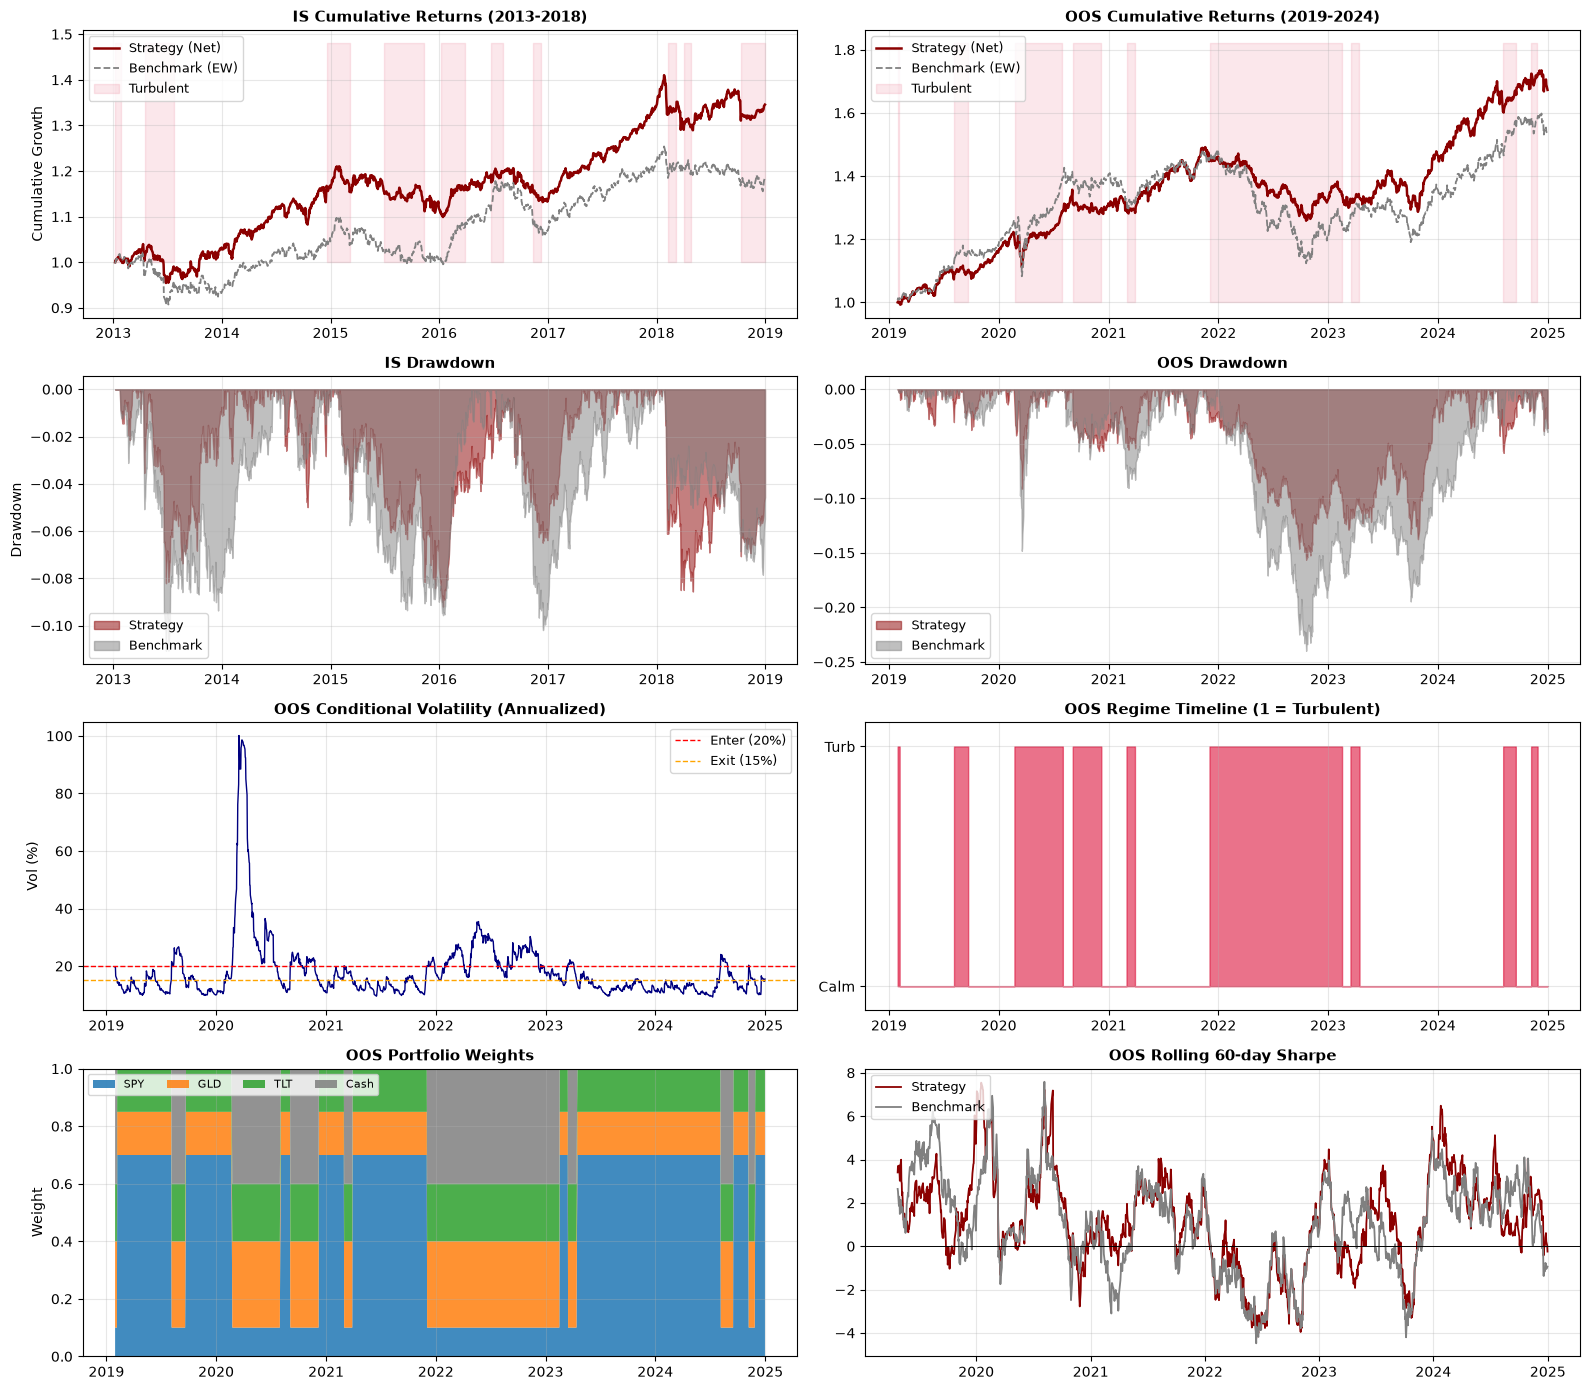

In [12]:
# Cell 11: Final dashboard (IS + OOS)

fig = plt.figure(figsize=(16, 14))

# Panel 1: IS cumulative returns
ax1 = plt.subplot2grid((4, 2), (0, 0))
ax1.plot(allocation_is['cum_net'].index, allocation_is['cum_net'],
         label='Strategy (Net)', color='darkred', lw=1.8)
ax1.plot(allocation_is['cum_bench'].index, allocation_is['cum_bench'],
         label='Benchmark (EW)', color='gray', lw=1.3, ls='--')
turb_mask_is = regime_is['regimes'] == 1
ax1.fill_between(regime_is['regimes'].index,
                 1, allocation_is['cum_net'].max() * 1.05,
                 where=turb_mask_is, color='crimson', alpha=0.10,
                 label='Turbulent')
ax1.set_title('IS Cumulative Returns (2013-2018)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Cumulative Growth')
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(alpha=0.3)

# Panel 2: OOS cumulative returns
ax2 = plt.subplot2grid((4, 2), (0, 1))
ax2.plot(allocation_oos['cum_net'].index, allocation_oos['cum_net'],
         label='Strategy (Net)', color='darkred', lw=1.8)
ax2.plot(allocation_oos['cum_bench'].index, allocation_oos['cum_bench'],
         label='Benchmark (EW)', color='gray', lw=1.3, ls='--')
turb_mask_oos = allocation_oos['regimes'] == 1
ax2.fill_between(allocation_oos['regimes'].index,
                 1, allocation_oos['cum_net'].max() * 1.05,
                 where=turb_mask_oos, color='crimson', alpha=0.10,
                 label='Turbulent')
ax2.set_title('OOS Cumulative Returns (2019-2024)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper left', fontsize=9)
ax2.grid(alpha=0.3)

# Panel 3: IS drawdown
ax3 = plt.subplot2grid((4, 2), (1, 0))
dd_net_is = (allocation_is['cum_net'] / allocation_is['cum_net'].cummax()) - 1
dd_bench_is = (allocation_is['cum_bench'] / allocation_is['cum_bench'].cummax()) - 1
ax3.fill_between(dd_net_is.index, dd_net_is, 0, color='darkred', alpha=0.5, label='Strategy')
ax3.fill_between(dd_bench_is.index, dd_bench_is, 0, color='gray', alpha=0.5, label='Benchmark')
ax3.set_title('IS Drawdown', fontsize=11, fontweight='bold')
ax3.set_ylabel('Drawdown')
ax3.legend(loc='lower left', fontsize=9)
ax3.grid(alpha=0.3)

# Panel 4: OOS drawdown
ax4 = plt.subplot2grid((4, 2), (1, 1))
dd_net_oos = (allocation_oos['cum_net'] / allocation_oos['cum_net'].cummax()) - 1
dd_bench_oos = (allocation_oos['cum_bench'] / allocation_oos['cum_bench'].cummax()) - 1
ax4.fill_between(dd_net_oos.index, dd_net_oos, 0, color='darkred', alpha=0.5, label='Strategy')
ax4.fill_between(dd_bench_oos.index, dd_bench_oos, 0, color='gray', alpha=0.5, label='Benchmark')
ax4.set_title('OOS Drawdown', fontsize=11, fontweight='bold')
ax4.legend(loc='lower left', fontsize=9)
ax4.grid(alpha=0.3)

# Panel 5: OOS Conditional vol with thresholds
ax5 = plt.subplot2grid((4, 2), (2, 0))
ax5.plot(allocation_oos['conditional_vol'].index,
         allocation_oos['conditional_vol'] * np.sqrt(252) * 100,
         color='navy', lw=1)
ax5.axhline(VOL_ENTER_ANN * 100, color='red', ls='--', lw=1,
            label=f'Enter ({VOL_ENTER_ANN*100:.0f}%)')
ax5.axhline(VOL_EXIT_ANN * 100, color='orange', ls='--', lw=1,
            label=f'Exit ({VOL_EXIT_ANN*100:.0f}%)')
ax5.set_title('OOS Conditional Volatility (Annualized)', fontsize=11, fontweight='bold')
ax5.set_ylabel('Vol (%)')
ax5.legend(loc='upper right', fontsize=9)
ax5.grid(alpha=0.3)

# Panel 6: OOS Regime timeline
ax6 = plt.subplot2grid((4, 2), (2, 1))
ax6.fill_between(allocation_oos['regimes'].index,
                 0, allocation_oos['regimes'],
                 color='crimson', alpha=0.6, step='mid')
ax6.set_title('OOS Regime Timeline (1 = Turbulent)', fontsize=11, fontweight='bold')
ax6.set_ylim(-0.1, 1.1)
ax6.set_yticks([0, 1])
ax6.set_yticklabels(['Calm', 'Turb'])
ax6.grid(alpha=0.3)

# Panel 7: OOS Portfolio weights (stacked)
ax7 = plt.subplot2grid((4, 2), (3, 0))
w = allocation_oos['weights']
ax7.stackplot(w.index,
              w['SPY'], w['GLD'], w['TLT'], w['Cash'],
              labels=['SPY', 'GLD', 'TLT', 'Cash'],
              colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#7f7f7f'],
              alpha=0.85)
ax7.set_title('OOS Portfolio Weights', fontsize=11, fontweight='bold')
ax7.set_ylabel('Weight')
ax7.set_ylim(0, 1)
ax7.legend(loc='upper left', fontsize=8, ncol=4)
ax7.grid(alpha=0.3)

# Panel 8: OOS Rolling 60-day Sharpe
ax8 = plt.subplot2grid((4, 2), (3, 1))
roll_s = (allocation_oos['net_returns'].rolling(60).mean() /
          allocation_oos['net_returns'].rolling(60).std()) * np.sqrt(252)
roll_b = (allocation_oos['benchmark'].rolling(60).mean() /
          allocation_oos['benchmark'].rolling(60).std()) * np.sqrt(252)
ax8.plot(roll_s.index, roll_s, label='Strategy', color='darkred', lw=1.3)
ax8.plot(roll_b.index, roll_b, label='Benchmark', color='gray', lw=1.3)
ax8.axhline(0, color='black', lw=0.7)
ax8.set_title('OOS Rolling 60-day Sharpe', fontsize=11, fontweight='bold')
ax8.legend(loc='upper left', fontsize=9)
ax8.grid(alpha=0.3)

plt.tight_layout()

# Save dashboard for GitHub
import os
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/dashboard.png', dpi=150, bbox_inches='tight')

plt.show()